<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · Reconcile SQL amounts with generated documents

**Does a merged document preserve every customer summary and its rounded amounts?**
Start with ten synthetic order lines for five fictional organizations, compute a
discount in exact decimal SQL, and ask the real worker to render individual DOCX
files and one merged batch. Check the resulting document text against the SQL
values before comparing package sizes.

All names, order lines and amounts are **synthetic demonstration data**. Units are
USD; tax, shipping and real billing rules are excluded. Nothing is purchased,
billed or sent. The companion template contains placeholders and no arithmetic.
Python inspects the returned ZIP/XML and draws charts; the VGI worker performs
all document rendering and merging.

## Set one discount parameter

`DISCOUNT_PCT` is a whole percent from **0 through 50**, default **10**. Apply it to
each customer's gross total, round that customer's discount to the nearest cent
(half away from zero), then subtract it from gross. Do **not** round a single batch
discount and allocate it later. That is a different rounding policy.

Restart and run all after changes. The focused experiment is **10 → 15 percent**;
the source rows and template stay fixed. Dates and external data sources are not
part of this deterministic example.

In [1]:
DISCOUNT_PCT = 10  # Whole percent, 0–50; experiment 15

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from notebook_support import chart, cleanup, configure, inspect_documents, prose, theme

previous_env, document_dir, run_at = configure(DISCOUNT_PCT)
source = (
    "Source: synthetic notebook order lines · real docgen v0.4.0 DOCX output · USD, excluding tax/shipping"
)
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-docgen-portable-xv02v4ph/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-docgen-portable-xv02v4ph/pyproject.toml.

## Attach the pinned remote worker

This literal `uvx` command installs remote tag **v0.4.0**, commit
`962d95bc0119361e6264d3bb9289346c60299ee0`, with the SDK, RPC, Arrow and document
library versions from the tested worker lock. It needs uv, Git and first-run
downloads, with no parent checkout or local worker build.

Discover the worker's bundled template to see its metadata. The investigation
then uses our [companion template](templates/README.md), whose extra fields expose
the rounding calculation in the resulting documents.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'docgen' AS docgen (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with docxtpl==0.20.2 --with docxcompose==2.2.0 --with python-docx==1.2.0 --from git+https://github.com/Query-farm/vgi-docgen@v0.4.0 vgi-docgen');
SELECT name, field_count, fields, description FROM docgen.main.sample_templates;

,name,field_count,fields,description
0,sample_invoice,2,"customer, total",A minimal single-page invoice template with a ...


## Build the exact customer totals

The ten source lines are visible here. Unit prices use **DECIMAL(12,2)** and
quantities are positive integers. Aggregate before applying a customer-level
discount. Integer division is avoided, and formatting for the document is kept
separate from the amounts used in arithmetic.

In [4]:
%%sql
CREATE TABLE lines AS
SELECT customer_id, customer, item, quantity::INTEGER AS quantity,
       unit_price::DECIMAL(12,2) AS unit_price
FROM (VALUES
 ('C01','Acorn Studio','Notebook',3,12.50),
 ('C01','Acorn Studio','Pen',2,3.75),
 ('C02','Beacon Workshop','Cable',4,8.95),
 ('C02','Beacon Workshop','Adapter',2,24.99),
 ('C03','Cedar Lab','Sensor',3,37.25),
 ('C03','Cedar Lab','Case',1,14.50),
 ('C04','Delta School','Kit',12,18.40),
 ('C04','Delta School','Labels',6,2.15),
 ('C05','Elm Library','Book',7,16.99),
 ('C05','Elm Library','Bag',3,4.50)
) AS t(customer_id, customer, item, quantity, unit_price);
CREATE TABLE amounts AS
WITH gross AS (
 SELECT customer_id, customer, sum(quantity*unit_price)::DECIMAL(12,2) AS gross_usd
 FROM lines GROUP BY customer_id, customer
), discounted AS (
 SELECT *, round(gross_usd * ({{DISCOUNT_PCT}}::DECIMAL(5,2) * 0.01::DECIMAL(3,2)),2)
              ::DECIMAL(12,2) AS discount_usd FROM gross
)
SELECT *, (gross_usd-discount_usd)::DECIMAL(12,2) AS net_usd FROM discounted;
SELECT * FROM amounts ORDER BY customer_id;

,customer_id,customer,gross_usd,discount_usd,net_usd
0,C01,Acorn Studio,45.00,4.50,40.50
1,C02,Beacon Workshop,85.78,8.58,77.20
2,C03,Cedar Lab,126.25,12.63,113.62
3,C04,Delta School,233.70,23.37,210.33
4,C05,Elm Library,132.43,13.24,119.19


In [5]:
%%sql rounding_frame <<
SELECT sum(gross_usd)::DECIMAL(12,2) AS gross_usd,
       sum(discount_usd)::DECIMAL(12,2) AS customer_discounts_usd,
       round(sum(gross_usd)*({{DISCOUNT_PCT}}::DECIMAL(5,2)*0.01::DECIMAL(3,2)),2)
           ::DECIMAL(12,2) AS hypothetical_batch_discount_usd,
       (sum(discount_usd)-round(sum(gross_usd)*({{DISCOUNT_PCT}}::DECIMAL(5,2)*0.01::DECIMAL(3,2)),2))
           ::DECIMAL(12,2) AS rounding_difference_usd,
       sum(net_usd)::DECIMAL(12,2) AS net_usd
FROM amounts;

In [6]:
display(rounding_frame)
r = rounding_frame.iloc[0]
prose(
    f"The source gross is **USD {r.gross_usd:,.2f}**. At **{DISCOUNT_PCT}%**, "
    f"the sum of customer discounts is **USD {r.customer_discounts_usd:,.2f}**, "
    f"leaving **USD {r.net_usd:,.2f}** across the five summaries. "
    f"Rounding one batch discount instead would give USD {r.hypothetical_batch_discount_usd:,.2f}; "
    f"the customer-minus-batch difference is **USD {r.rounding_difference_usd:+.2f}**. "
    + (
        "The methods agree for this parameter, but that agreement is not a general identity."
        if r.rounding_difference_usd == 0
        else "The rounding levels differ. The documents use the customer rule."
    )
)

,gross_usd,customer_discounts_usd,hypothetical_batch_discount_usd,rounding_difference_usd,net_usd
0,623.16,62.32,62.32,0.0,560.84


The source gross is **USD 623.16**. At **10%**, the sum of customer discounts is **USD 62.32**, leaving **USD 560.84** across the five summaries. Rounding one batch discount instead would give USD 62.32; the customer-minus-batch difference is **USD +0.00**. The methods agree for this parameter, but that agreement is not a general identity.

## Render each summary, then merge the same contexts

The six template fields are strings, including exactly two decimals for amounts.
Materialize each worker operation once before DataFrame capture. Scalar rendering
produces one BLOB per customer; the buffering merge consumes all customer contexts
and emits one BLOB. We verify content as a collection of summaries, so no guarantee
about parallel merge order is needed.

In [7]:
%%sql
CREATE TABLE contexts AS
SELECT customer_id, customer,
       gross_usd::VARCHAR AS gross_text,
       {{DISCOUNT_PCT}}::VARCHAR AS discount_pct_text,
       discount_usd::VARCHAR AS discount_text,
       net_usd::VARCHAR AS net_text
FROM amounts;
CREATE TABLE individual_docs AS
SELECT c.*, docgen.main.docgen_render('templates/order_summary.docx',
    {customer_id: c.customer_id, customer: c.customer, gross_text: c.gross_text,
     discount_pct_text: c.discount_pct_text, discount_text: c.discount_text, net_text: c.net_text}) AS doc
FROM contexts c;
CREATE TABLE merged_docs AS
SELECT * FROM docgen.main.docgen_merge(
    (SELECT * FROM contexts ORDER BY customer_id), template := 'templates/order_summary.docx');
SELECT customer_id, octet_length(doc) AS docx_bytes, doc[1:2] = 'PK'::BLOB AS zip_header
FROM individual_docs ORDER BY customer_id;

,customer_id,docx_bytes,zip_header
0,C01,36856,True
1,C02,36862,True
2,C03,36859,True
3,C04,36861,True
4,C05,36862,True


## Inspect the actual returned document content

A ZIP header alone does not prove a correct document. Inspect CRCs and the main
Word document XML, compare every paragraph with SQL-formatted values, then require
that the merged document contains exactly one copy of every customer block. This
checks content and multiplicity, not page layout or compatibility with every
Word/LibreOffice version. No PDF conversion or office application is required.

In [8]:
rows = con.execute("SELECT * FROM individual_docs ORDER BY customer_id").fetchall()
merged = con.execute("SELECT doc FROM merged_docs").fetchone()[0]
content_checks, merged_paragraphs = inspect_documents(rows, merged, document_dir)
display(pd.DataFrame(content_checks))
prose(
    "**All document paragraphs match SQL**, and the merged file contains each customer block exactly once. "
    "The first customer summary reads:"
)
display(pd.DataFrame({"paragraph": merged_paragraphs[:8]}))
prose(
    f"Generated DOCX files: [{document_dir}/]({document_dir.as_posix()}/). "
    f"Open [the merged document]({(document_dir / 'merged.docx').as_posix()}) to inspect layout. "
    f"Execution time: `{run_at}` (UTC); amounts and source rows have no time dimension."
)

,customer_id,paragraphs_match_sql,net_usd_text
0,C01,True,40.50
1,C02,True,77.20
2,C03,True,113.62
3,C04,True,210.33
4,C05,True,119.19


**All document paragraphs match SQL**, and the merged file contains each customer block exactly once. The first customer summary reads:

,paragraph
0,SYNTHETIC ORDER SUMMARY
1,Customer ID: C01
2,Customer: Acorn Studio
3,Currency: USD; synthetic example; tax and ship...
4,Gross USD: 45.00
5,Discount 10% USD: 4.50
6,Net USD: 40.50
7,"Demonstration only. No order is placed, billed..."


Generated DOCX files: [artifacts/generated/discount-10pct/](artifacts/generated/discount-10pct/). Open [the merged document](artifacts/generated/discount-10pct/merged.docx) to inspect layout. Execution time: `2026-11-14T06:19:31.550668+00:00` (UTC); amounts and source rows have no time dimension.

## Compare the amounts that reached the documents

Each bar adds net amount and discount back to the source gross. This uses the
exact SQL results converted to numbers only for plotting. All customer bars share
a zero-based USD axis. Customer-level rounding is already complete.

In [9]:
%%sql amount_frame <<
SELECT * FROM amounts ORDER BY gross_usd DESC, customer_id;

findfont: Failed to find font weight semibold for Arial, now using 700.


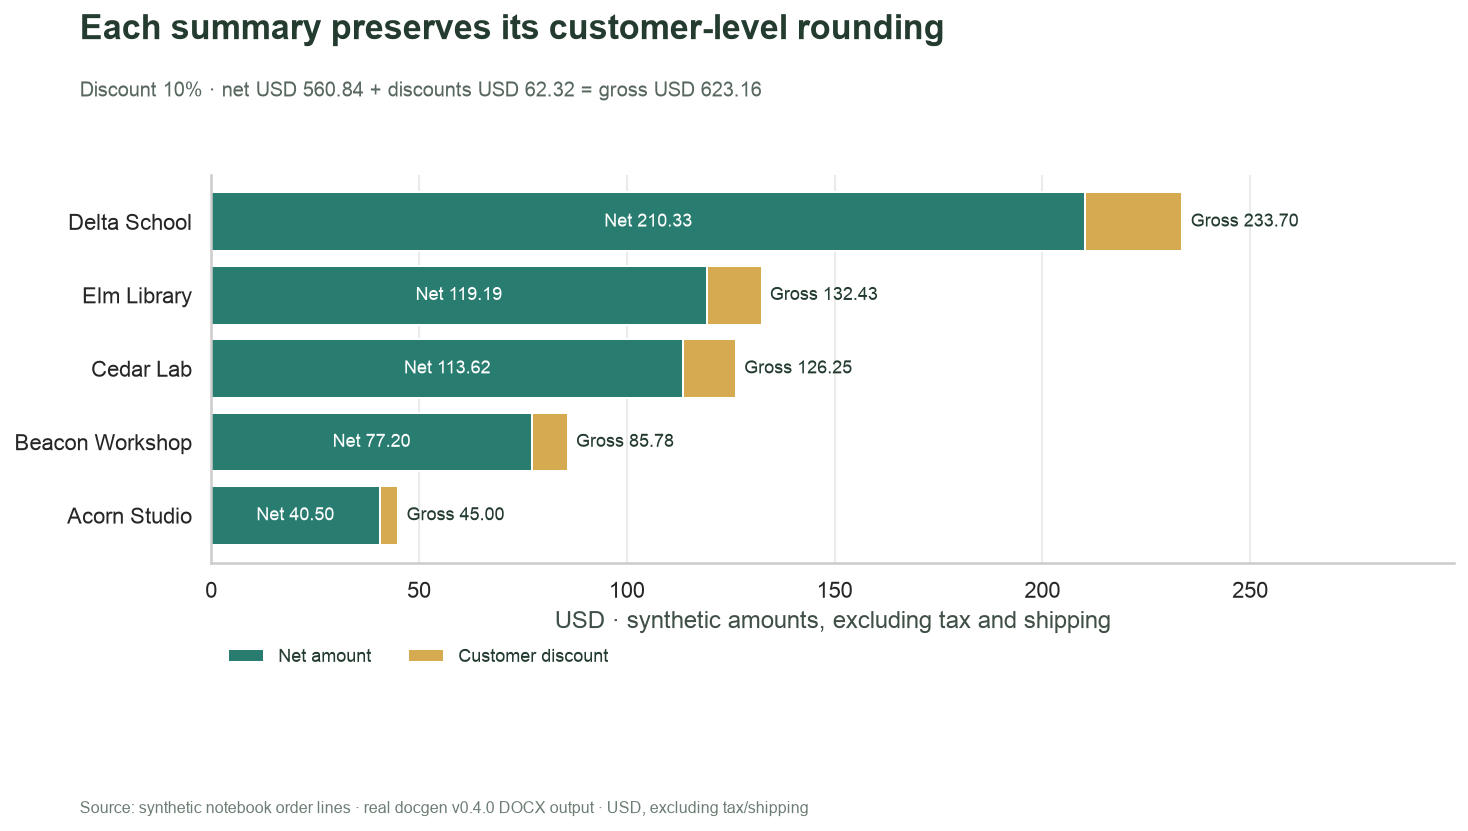

In [10]:
fig, ax = plt.subplots(figsize=(10.5, 5.8))
a = amount_frame
ax.barh(a.customer, a.net_usd, color="#287D70", label="Net amount")
ax.barh(a.customer, a.discount_usd, left=a.net_usd, color="#D5AA50", label="Customer discount")
for i, row in enumerate(a.itertuples()):
    ax.text(row.net_usd / 2, i, f"Net {row.net_usd:.2f}", ha="center", va="center", color="white", fontsize=9)
    ax.text(row.gross_usd + 2, i, f"Gross {row.gross_usd:.2f}", va="center", fontsize=9)
ax.invert_yaxis()
ax.set(xlabel="USD · synthetic amounts, excluding tax and shipping", xlim=(0, a.gross_usd.max() * 1.28))
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.18), ncol=2, fontsize=9)
ax.grid(axis="y", visible=False)
chart(
    fig,
    "Each summary preserves its customer-level rounding",
    f"Discount {DISCOUNT_PCT}% · net USD {r.net_usd:,.2f} "
    f"+ discounts USD {r.customer_discounts_usd:,.2f} = gross USD {r.gross_usd:,.2f}",
    source,
)

## Compare packaging, with content held fixed

DOCX is a ZIP package with document parts and shared resources. Adding the byte
lengths of individual files counts those parts repeatedly; a merged package has a
different structure and compression behavior. Measure actual worker outputs.
This is a small-file packaging comparison, not a performance benchmark or a claim
that every template will compress similarly.

In [11]:
%%sql package_frame <<
SELECT 'Individual files combined' AS packaging, count(*) AS file_count,
       sum(octet_length(doc)) AS bytes FROM individual_docs
UNION ALL
SELECT 'One merged file', count(*), sum(octet_length(doc)) FROM merged_docs;

,packaging,file_count,bytes
0,Individual files combined,5,184300.0
1,One merged file,1,37034.0


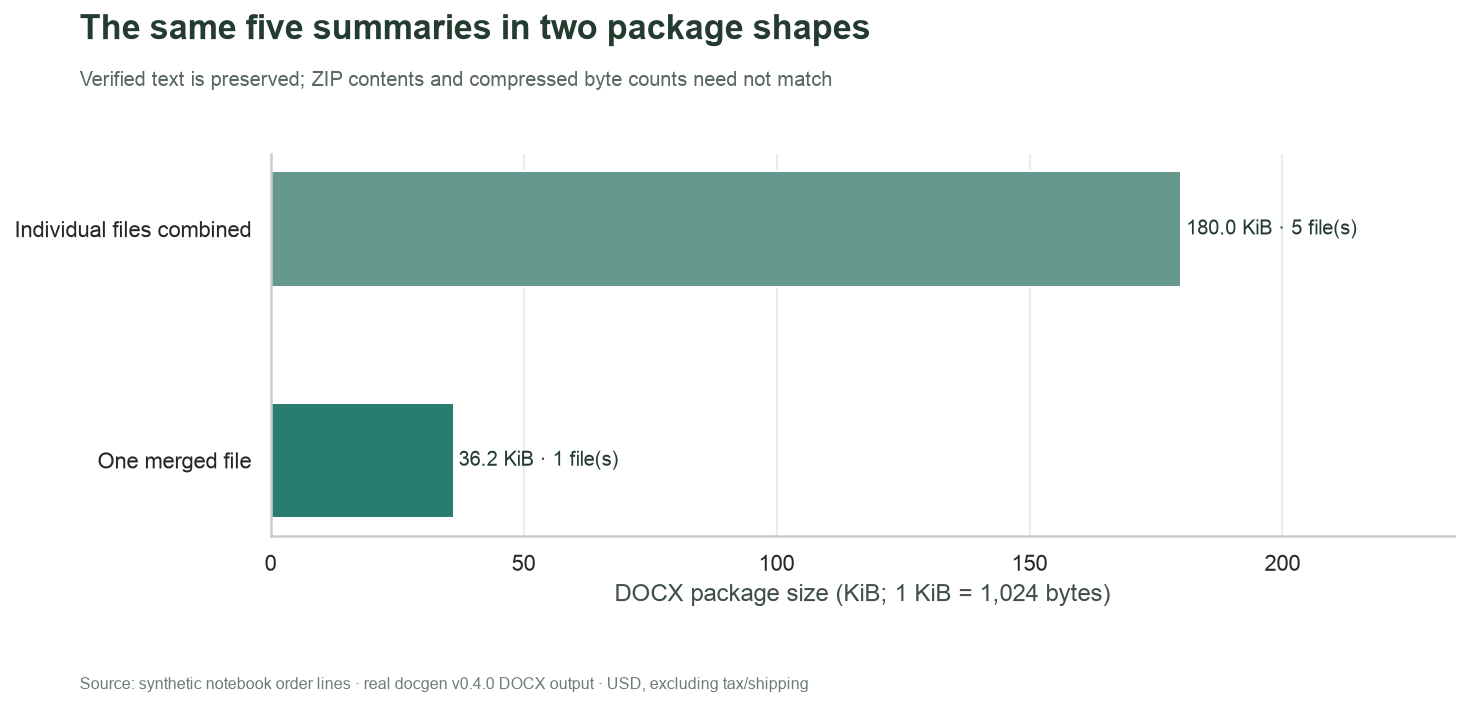

The merged file uses **37,034 bytes**, versus **184,300 bytes** across the five individual files: **79.9% less** in this run. Its five customer summaries still match exactly. ZIP metadata and compression can change byte sizes without changing text, so file hashes and byte savings are not semantic correctness tests.

In [12]:
display(package_frame)
fig, ax = plt.subplots(figsize=(10.5, 4.9))
p = package_frame
ax.barh(p.packaging, p.bytes / 1024, color=["#66988E", "#287D70"], height=0.5)
for i, row in enumerate(p.itertuples()):
    ax.text(
        row.bytes / 1024 + 1,
        i,
        f"{row.bytes / 1024:.1f} KiB · {row.file_count} file(s)",
        va="center",
        fontsize=10,
    )
ax.invert_yaxis()
ax.set(xlabel="DOCX package size (KiB; 1 KiB = 1,024 bytes)", xlim=(0, p.bytes.max() / 1024 * 1.3))
ax.grid(axis="y", visible=False)
chart(
    fig,
    "The same five summaries in two package shapes",
    "Verified text is preserved; ZIP contents and compressed byte counts need not match",
    source,
)
individual_bytes = int(p.loc[p.packaging == "Individual files combined", "bytes"].iloc[0])
merged_bytes = int(p.loc[p.packaging == "One merged file", "bytes"].iloc[0])
change = 100 * (individual_bytes - merged_bytes) / individual_bytes
prose(
    f"The merged file uses **{merged_bytes:,} bytes**, versus **{individual_bytes:,} bytes** "
    f"across the five individual files: **{abs(change):.1f}% "
    + ("less" if change >= 0 else "more")
    + "** in this run. "
    "Its five customer summaries still match exactly. ZIP metadata and compression can change byte sizes "
    "without changing text, so file hashes and byte savings are not semantic correctness tests."
)

## Check arithmetic, cardinality and failure handling

A scalar render failure returns NULL, so a row count alone cannot establish
success. Check non-NULL output explicitly. The deliberately invalid template
below must return NULL and a subsequent valid render must succeed. An empty
merge input produces zero output rows, rather than one empty document.
The exact-content inspection above is a separate check beyond these SQL invariants.

In [13]:
%%sql checks <<
SELECT 'Positive quantities and nonnegative prices' AS check_name,
       bool_and(quantity > 0 AND unit_price >= 0) AS passed FROM lines
UNION ALL SELECT 'One summary per customer',
       (SELECT count(*) FROM amounts) = count(DISTINCT customer_id) FROM lines
UNION ALL SELECT 'Gross agrees with source line extension',
       (SELECT sum(gross_usd) FROM amounts) = sum(quantity*unit_price) FROM lines
UNION ALL SELECT 'Exact per-customer reconciliation',
       bool_and(net_usd+discount_usd=gross_usd AND discount_usd>=0 AND net_usd>=0) FROM amounts
UNION ALL SELECT 'No scalar render failure',
       count(*)=(SELECT count(*) FROM amounts) AND bool_and(doc IS NOT NULL AND octet_length(doc)>0)
       FROM individual_docs
UNION ALL SELECT 'Exactly one nonempty merged document',
       count(*)=1 AND bool_and(doc IS NOT NULL AND octet_length(doc)>0) FROM merged_docs
UNION ALL SELECT 'Malformed scalar template returns NULL',
       docgen.main.docgen_render('not a DOCX'::BLOB, {customer:'Synthetic'}) IS NULL
UNION ALL SELECT 'Empty merge input returns no document', count(*)=0
       FROM docgen.main.docgen_merge((SELECT * FROM contexts WHERE false),
                                    template := 'templates/order_summary.docx');

In [14]:
%%sql recovery <<
SELECT docgen.main.docgen_render('templates/order_summary.docx',
       {customer_id:'CHECK', customer:'Synthetic check', gross_text:'0.00', discount_pct_text:'0',
        discount_text:'0.00', net_text:'0.00'}) IS NOT NULL AS worker_still_responds;

In [15]:
display(checks)
display(recovery)
assert checks.passed.fillna(False).all(), "A SQL invariant failed"
assert recovery.worker_still_responds.all(), "The post-error valid render failed"
prose(
    f"**{len(checks)} SQL invariants, recovery and all document-content checks passed.** "
    "This establishes that these synthetic inputs survived the selected template and rendering path. "
    "It does not validate a real billing policy or the appearance of complex tables, fonts or images."
)

,check_name,passed
0,Positive quantities and nonnegative prices,True
1,One summary per customer,True
2,Gross agrees with source line extension,True
3,Exact per-customer reconciliation,True
4,No scalar render failure,True
5,Exactly one nonempty merged document,True
6,Malformed scalar template returns NULL,True
7,Empty merge input returns no document,True


,worker_still_responds
0,True


**8 SQL invariants, recovery and all document-content checks passed.** This establishes that these synthetic inputs survived the selected template and rendering path. It does not validate a real billing policy or the appearance of complex tables, fonts or images.

## Experiment · change only the discount

Change **DISCOUNT_PCT from 10 to 15**. Predict a lower net total, unchanged source
gross, unchanged customer/document counts, and different rendered amounts. Also
compare **customer_discounts_usd** with **hypothetical_batch_discount_usd**: rounding
at different levels may now separate values that agreed at 10%.

```sh
uv run --locked python execute.py --timeout 300 \
  --parameters '{"DISCOUNT_PCT": 15}' --output-dir artifacts/discount-15
```

Compare the amount chart and document-text checks first; compressed byte counts
may move for incidental reasons. Reset to **10** afterward. Generated documents
and experiment copies are ignored, while the successful default notebook retains
its embedded outputs. The runner copies templates and generated files beside the
experiment for review.

In [16]:
con.close()
cleanup(previous_env)
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)